In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats.distributions import chi2
from ipywidgets import interact, FloatSlider
from scipy import stats

# **Input**

Import files:
<br>From surfdrive and given student numbers gives us Z_23.3.dat file<br>

In [3]:
filenames = [
    'Z_02.7.dat',
    'Z_07.3.dat',
    'Z_10.6.dat',
    'Z_16.8.dat',
    'Z_23.3.dat',
    'Z_29.7.dat',
    'Z_36.0.dat',
    'Z_42.4.dat',
    'Z_48.8.dat',
    'Z_55.3.dat',
    'Z_61.5.dat',
    'Z_74.4.dat',
    'Z_87.0.dat',
    'Z_94.4.dat']

# Given values based on student ID 
H = 30 # m
U = 1 # m / s
K = 0.41 # von Karman

Make function:
<br>Gives us the height value wrt the bed (using file names)<br>

In [4]:
def get_z(name, h):
    value = float(name.split('_')[1].replace('.dat', ''))
    return value * 0.01 * h

proof of concept

In [5]:
# data4 = np.loadtxt(filenames[4])  # Load the data for 'Z_23.3.dat'

# print(f'{get_z(filenames[4], 100)}% height') 

# tst = data4[:, 0]
# ust = data4[:, 1]
# vst = data4[:, 2]

# ust.mean(), ust.std()
# plt.plot(tst, ust, label='ust')
# plt.plot(tst, np.ones(len(tst)) * ust.mean(), 'r--', label='mean');
# print(f'Mean: {ust.mean():.4f}, Std: {ust.std():.4f}')

# **Result**

In [6]:
zheights = [get_z(item, H) for item in filenames]
avgu = np.zeros(len(filenames))

for item in filenames:
    data = np.loadtxt(item)
    tst = data[:, 0]
    ust = data[:, 1]
    vst = data[:, 2]
    avgu[filenames.index(item)] = ust.mean()

dimavgu = avgu * U

# print(avgu)
# print(zheights)

In [7]:
fitdat = np.polyfit(np.log(zheights)/K, dimavgu, 1)  # Fit a linear model to 1/Klog(z) vs avgu

a = fitdat[0]
print(f'Fitted parameters: {fitdat[0]:.4f}, {fitdat[1]:.4f}')

Fitted parameters: 0.0878, 0.4837


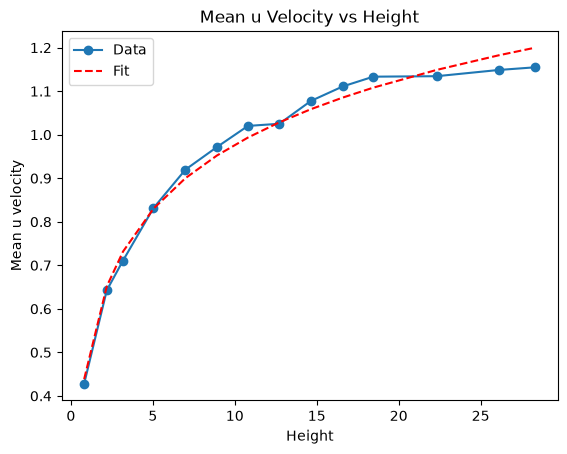

In [8]:
plt.plot(zheights, dimavgu, 'o-', label='Data')
plt.xlabel('Height')
plt.ylabel('Mean u velocity')
plt.title('Mean u Velocity vs Height');
plt.plot(zheights, np.polyval(fitdat, np.log(zheights)/K), 'r--', label='Fit')
plt.legend();

In [9]:
print(f'Log-profile given by a = 1 / K * ln(b)')
print(f'Fitting the formula to the data, we get a = {fitdat[0]:.4f} and b = {fitdat[1]:.4f}')

print(avgu / fitdat[0])

Log-profile given by a = 1 / K * ln(b)
Fitting the formula to the data, we get a = 0.0878 and b = 0.4837
[ 4.87358416  7.31610869  8.09418016  9.46885967 10.47395284 11.06394332
 11.61664473 11.67372875 12.26943724 12.6503278  12.90511599 12.91769296
 13.08029762 13.15004136]


# Reynolds Stress Extrapolation

In [10]:
U_mean = np.mean(avgu)
h_depth = H     
rho = 1000   
print(avgu)

[0.42801102 0.64251997 0.71085226 0.83158025 0.91985018 0.9716647
 1.0202044  1.02521767 1.07753436 1.11098517 1.13336134 1.13446589
 1.14874626 1.15487134]


In [11]:
avgu_array = np.zeros(len(filenames))
cov_array = np.zeros(len(filenames))
tau_array = np.zeros(len(filenames))

for i in range(len(filenames)):
    file = filenames[i]
    z_val = zheights[i]
   
    data = np.loadtxt(file)
    ust = data[:, 1] # u~
    vst = data[:, 2] # v~
    
    # Calculate covariance and stress
    # COVARIANCE = bar(ui' - uj'), i.e., the average of the product of deviations 
    cov_tilde = (ust * vst).mean() - (ust.mean() * vst.mean())
    tau_R = -rho * (U**2) * cov_tilde # multiply by U**2 to get the correct units for stress
    
    # Store the results in the arrays at index i
    avgu_array[i] = ust.mean()
    cov_array[i] = cov_tilde
    tau_array[i] = tau_R
    


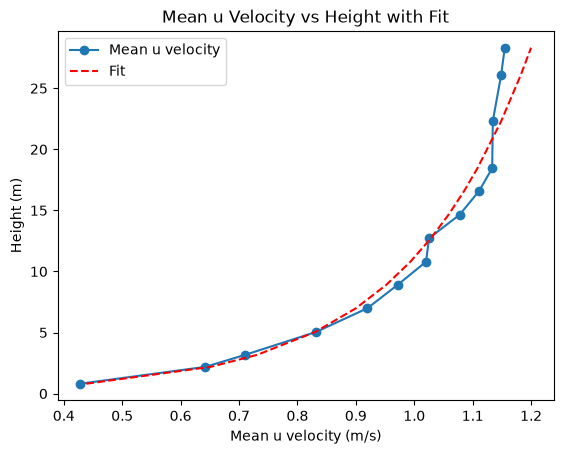

In [12]:
plt.plot(avgu_array, zheights, 'o-', label='Mean u velocity')
plt.plot(np.polyval(fitdat, np.log(zheights)/K), zheights, 'r--', label='Fit')
plt.ylabel('Height (m)')
plt.xlabel('Mean u velocity (m/s)')
plt.title('Mean u Velocity vs Height with Fit')
plt.legend();

In [13]:
print(len(tau_array), len(filenames) - 1)

14 13


In [101]:
print(zrange[0])
print(zrange[1])

[0.81, 2.19, 3.1799999999999997, 5.04, 6.99, 8.91, 10.799999999999999, 12.719999999999999, 14.64, 16.589999999999996, 18.45, 22.320000000000004, 26.1]
[2.19, 3.1799999999999997, 5.04, 6.99, 8.91, 10.799999999999999, 12.719999999999999, 14.64, 16.589999999999996, 18.45, 22.320000000000004, 26.1, 28.32]


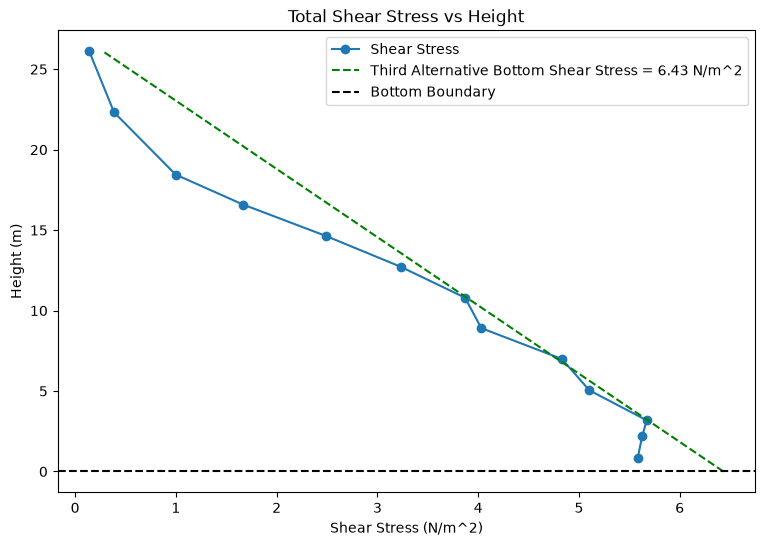

In [108]:
case = 0

mu = 1.0016
tau_z_array = np.zeros(len(filenames)-1)
tau_z_array2 = np.zeros(len(filenames)-1)
tau_z_array3 = np.zeros(len(filenames)-1)
for i in range(len(filenames) - 1):
    tau_z_array[i] = mu * (avgu_array[i+1] - avgu_array[i]) / (zheights[i+1] - zheights[i]) + tau_array[i+1]
    tau_z_array2[i] = mu * (avgu_array[i+1] - avgu_array[i]) / (zheights[i+1] - zheights[i]) + tau_array[i]

zrange = [zheights[:-1], zheights[1:]]

# Plotting the shear stress vs height
arrayset = [tau_z_array, tau_z_array2]

plt.figure(figsize=(9,6))
plt.plot(arrayset[case], zrange[case], 'o-', label='Shear Stress')
# plt.plot(tau_z_array2, zheights[1:], 's-', label='Alternative Shear Stress')
plt.ylabel('Height (m)')
plt.xlabel('Shear Stress (N/m^2)')

# Taking the last two points to fit a line and find the intercept at z=0 for bottom shear stress
slope, intercept = np.polyfit(zrange[case][:2], arrayset[case][:2], 1)
tau_at_zero = intercept

tauzeros = [tau_at_zero, tau_at_zero]


# Linear extrapolation

xset = np.linspace(0, max(zrange[case]), len(arrayset[case]))
slope, intercept = np.polyfit(xset, arrayset[case], deg=1)
tau_at_zero3 = intercept

plt.plot(xset*slope + intercept, xset, color='g', linestyle='--', label='Third Alternative Bottom Shear Stress = {:.2f} N/m^2'.format(tau_at_zero3))

# Plotting the bottom shear stress lines
# plt.plot([arrayset[case][0], tauzeros[case]], [zrange[case][0], 0], color='r', linestyle='--', label='Bottom Shear Stress = {:.2f} N/m^2'.format(tauzeros[case]))
plt.axhline(y=0, color='k', linestyle='--', label='Bottom Boundary')
plt.title('Total Shear Stress vs Height')
plt.legend();

### Extra overview

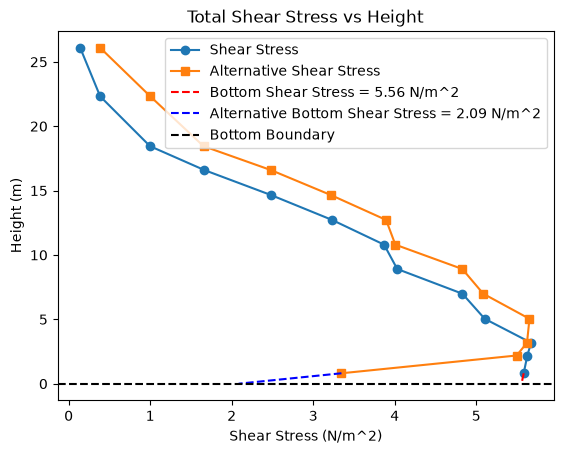

In [ ]:
mu = 1.0016
tau_z_array = np.zeros(len(filenames)-1)
tau_z_array2 = np.zeros(len(filenames)-1)
for i in range(len(filenames) - 1):
    tau_z_array[i] = mu * (avgu_array[i+1] - avgu_array[i]) / (zheights[i+1] - zheights[i]) + tau_array[i+1]
    tau_z_array2[i] = mu * (avgu_array[i+1] - avgu_array[i]) / (zheights[i+1] - zheights[i]) + tau_array[i]


plt.plot(tau_z_array, zheights[:-1], 'o-', label='Shear Stress')
plt.plot(tau_z_array2, zheights[:-1], 's-', label='Alternative Shear Stress')
plt.ylabel('Height (m)')
plt.xlabel('Shear Stress (N/m^2)')

slope, intercept = np.polyfit(zheights[:2], tau_z_array[:2], 1)
tau_at_zero = intercept

slope, intercept = np.polyfit(zheights[:2], tau_z_array2[:2], 1)
tau_at_zero2 = intercept

plt.plot([tau_z_array[0], tau_at_zero], [zheights[0], 0], color='r', linestyle='--', label='Bottom Shear Stress = {:.2f} N/m^2'.format(tau_at_zero))
plt.plot([tau_z_array2[0], tau_at_zero2], [zheights[0], 0], color='b', linestyle='--', label='Alternative Bottom Shear Stress = {:.2f} N/m^2'.format(tau_at_zero2))
plt.axhline(y=0, color='k', linestyle='--', label='Bottom Boundary')
plt.title('Total Shear Stress vs Height')
plt.legend();

Text(0, 0.5, 'Height (m)')

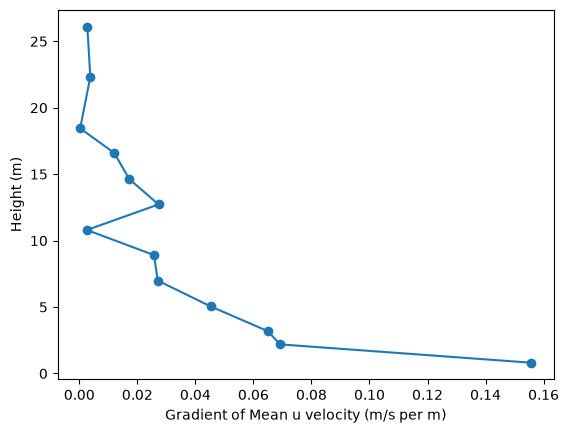

In [ ]:
checkray = np.zeros(len(filenames)-1)
for i in range(len(filenames) - 1):
    checkray[i] = mu * (avgu_array[i+1] - avgu_array[i]) / (zheights[i+1] - zheights[i])
plt.plot(checkray, zheights[:-1], 'o-')
# plt.plot(tau_array, zheights[:], 's-', label='Total Shear Stress')
plt.xlabel('Gradient of Mean u velocity (m/s per m)')
plt.ylabel('Height (m)')